In [1]:
### 08 – Mamdani Fuzzy Inference System

In [3]:
!pip install numpy matplotlib

In [4]:
import numpy as np
import matplotlib.pyplot as plt

In [5]:
# Triangular membership function

def trimf(x, a, b, c):

    return np.maximum(
        np.minimum(
            (x - a) / (b - a),
            (c - x) / (c - b)
        ),
        0
    )

In [6]:
# Input variable: Clothes (0 to 100)

clothes = np.linspace(0, 100, 101)

# Output variable: Time (0 to 60)

time = np.linspace(0, 60, 101)

print("Input Range: 0 to 100")
print("Output Range: 0 to 60")

Input Range: 0 to 100
Output Range: 0 to 60


In [11]:
# Input membership functions

clothes_less = trimf(clothes, 0, 10, 20)

clothes_moderate = trimf(clothes, 10, 40, 60)

clothes_high = trimf(clothes, 50, 60, 80)

print("Input Membership Functions Created")

Input Membership Functions Created


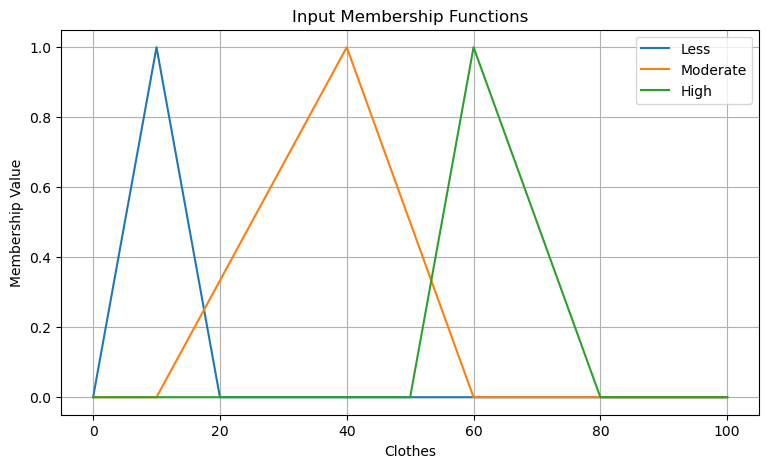

In [13]:
plt.figure(figsize=(9, 5))

plt.plot(clothes, clothes_less, label="Less")

plt.plot(clothes, clothes_moderate, label="Moderate")

plt.plot(clothes, clothes_high, label="High")

plt.xlabel("Clothes")
plt.ylabel("Membership Value")

plt.title("Input Membership Functions")

plt.legend()
plt.grid(True)

plt.show()

In [15]:
# Output membership functions

time_less = trimf(time, 0, 8, 15)

time_moderate = trimf(time, 10, 25, 40)

time_high = trimf(time, 30, 45, 60)

print("Output Membership Functions Created")

Output Membership Functions Created


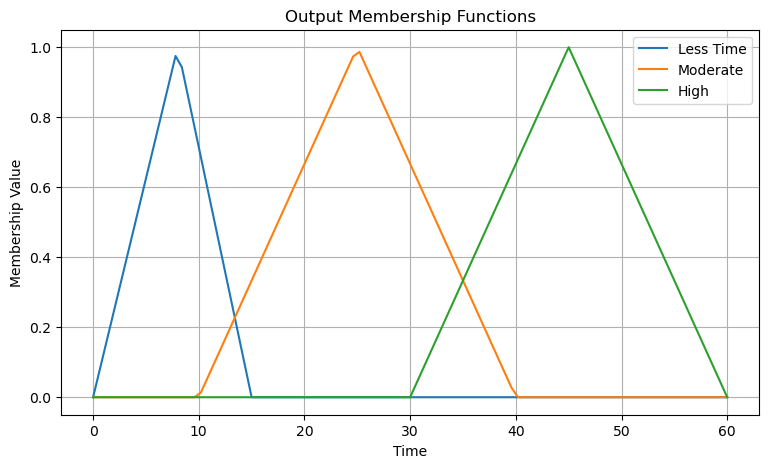

In [17]:
plt.figure(figsize=(9, 5))

plt.plot(time, time_less, label="Less Time")

plt.plot(time, time_moderate, label="Moderate")

plt.plot(time, time_high, label="High")

plt.xlabel("Time")
plt.ylabel("Membership Value")

plt.title("Output Membership Functions")

plt.legend()
plt.grid(True)

plt.show()

In [21]:
# Take input from user

clothes_input = float(input("Enter quantity of clothes (0-100): "))

# Calculate membership values

less_degree = np.interp(clothes_input, clothes, clothes_less)

moderate_degree = np.interp(clothes_input, clothes, clothes_moderate)

high_degree = np.interp(clothes_input, clothes, clothes_high)

print("\nFuzzification Results")

print("Less:", less_degree)

print("Moderate:", moderate_degree)

print("High:", high_degree)

Enter quantity of clothes (0-100):  56



Fuzzification Results
Less: 0.0
Moderate: 0.2
High: 0.6


In [23]:
# Define fuzzy rules

rules = [
    ("less", "less_time"),
    ("less", "moderate"),
    ("less", "high"),

    ("moderate", "less_time"),
    ("moderate", "moderate"),
    ("moderate", "high"),

    ("high", "less_time"),
    ("high", "moderate"),
    ("high", "high")
]

print("Total Rules:", len(rules))

for i, rule in enumerate(rules, 1):
    print(f"Rule {i}: If Clothes is {rule[0]} "
          f"Then Time is {rule[1]}")

Total Rules: 9
Rule 1: If Clothes is less Then Time is less_time
Rule 2: If Clothes is less Then Time is moderate
Rule 3: If Clothes is less Then Time is high
Rule 4: If Clothes is moderate Then Time is less_time
Rule 5: If Clothes is moderate Then Time is moderate
Rule 6: If Clothes is moderate Then Time is high
Rule 7: If Clothes is high Then Time is less_time
Rule 8: If Clothes is high Then Time is moderate
Rule 9: If Clothes is high Then Time is high


In [25]:
# Input membership values

input_membership = {
    "less": less_degree,
    "moderate": moderate_degree,
    "high": high_degree
}

# Output membership functions

output_membership = {
    "less_time": time_less,
    "moderate": time_moderate,
    "high": time_high
}

# Initialize aggregated output

aggregated_output = np.zeros(len(time))

# Apply Mamdani inference mechanism

for antecedent, consequent in rules:

    # Calculate rule strength
    strength = input_membership[antecedent]

    # Apply implication using minimum
    rule_output = np.minimum(
        strength,
        output_membership[consequent]
    )

    # Aggregate using maximum
    aggregated_output = np.maximum(
        aggregated_output,
        rule_output
    )

print("Rule Strength Calculation Completed")

Rule Strength Calculation Completed


In [27]:
# Centroid Defuzzification

numerator = np.trapz(
    aggregated_output * time,
    time
)

denominator = np.trapz(
    aggregated_output,
    time
)

if denominator != 0:

    crisp_output = numerator / denominator

else:

    crisp_output = 0

print("Final Washing Time:", round(crisp_output, 2))

Final Washing Time: 29.54


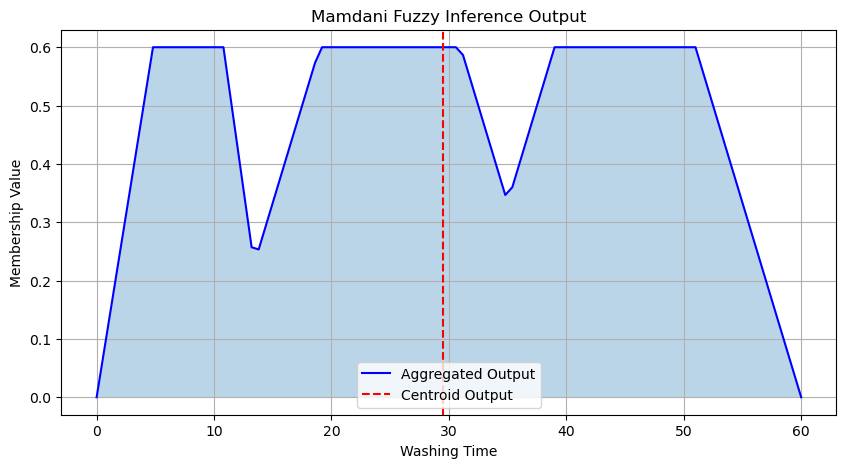

In [29]:
plt.figure(figsize=(10, 5))

plt.plot(
    time,
    aggregated_output,
    label="Aggregated Output",
    color="blue"
)

plt.fill_between(
    time,
    aggregated_output,
    alpha=0.3
)

plt.axvline(
    crisp_output,
    color="red",
    linestyle="--",
    label="Centroid Output"
)

plt.xlabel("Washing Time")

plt.ylabel("Membership Value")

plt.title("Mamdani Fuzzy Inference Output")

plt.legend()

plt.grid(True)

plt.show()

In [31]:
print("================================")
print(" MAMDANI FUZZY INFERENCE SYSTEM")
print("================================")

print("Input Clothes:", clothes_input)

print("\nFuzzification Values:")

print("Less:", round(less_degree, 3))

print("Moderate:", round(moderate_degree, 3))

print("High:", round(high_degree, 3))

print("\nFinal Washing Time:", round(crisp_output, 2))

print("\nFIS Implemented Successfully!")

 MAMDANI FUZZY INFERENCE SYSTEM
Input Clothes: 56.0

Fuzzification Values:
Less: 0.0
Moderate: 0.2
High: 0.6

Final Washing Time: 29.54

FIS Implemented Successfully!


In [33]:
# Test different clothes quantities

test_inputs = [10, 30, 50, 70]

for value in test_inputs:

    less = np.interp(value, clothes, clothes_less)

    moderate = np.interp(value, clothes, clothes_moderate)

    high = np.interp(value, clothes, clothes_high)

    input_values = {
        "less": less,
        "moderate": moderate,
        "high": high
    }

    output = np.zeros(len(time))

    for antecedent, consequent in rules:

        strength = input_values[antecedent]

        rule_output = np.minimum(
            strength,
            output_membership[consequent]
        )

        output = np.maximum(output, rule_output)

    denominator = np.trapz(output, time)

    if denominator != 0:
        result = np.trapz(output * time, time) / denominator
    else:
        result = 0

    print("Clothes:", value, "Washing Time:", round(result, 2))

Clothes: 10 Washing Time: 29.55
Clothes: 30 Washing Time: 29.54
Clothes: 50 Washing Time: 29.54
Clothes: 70 Washing Time: 29.54
